# <center>Визуализация данных PRO<center>

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

**1. Постройте heatmap, отображающий среднедневные продажи на разных страницах сайта в зависимости от времени и типа устройства пользователя по имеющимся данным.** 

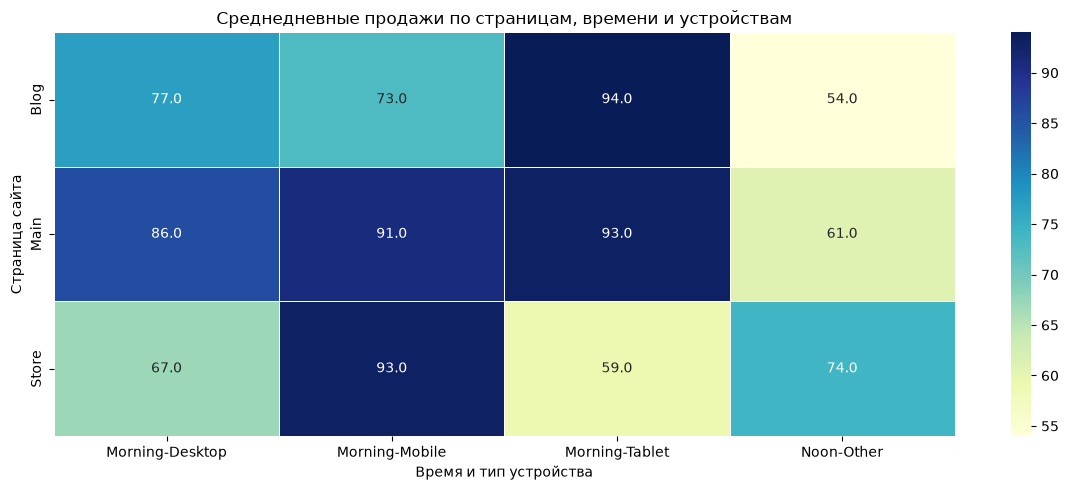

In [7]:
websites = ['Main', 'Main', 'Main', 'Main', 'Blog', 'Blog', 
            'Blog', 'Blog', 'Store', 'Store', 'Store', 'Store']
devices = ['Desktop', 'Mobile', 'Tablet', 'Other', 'Desktop', 
           'Mobile', 'Tablet', 'Other', 'Desktop', 'Mobile', 'Tablet', 'Other']
sales = np.random.randint(50, 100, size=12)
time = ['Morning', 'Morning', 'Morning', 'Noon', 'Morning', 'Morning', 
        'Morning', 'Noon', 'Morning', 'Morning', 'Morning', 'Noon']

df = pd.DataFrame({'Websites': websites, 'Devices': devices, 'Sales': sales, 'Time': time})


sales_pivot = df.pivot_table(
    index='Websites',
    columns=['Time', 'Devices'],
    values='Sales',
    aggfunc='mean'
)

plt.figure(figsize=(12, 5))
sns.heatmap(sales_pivot, annot=True, fmt='.1f', cmap='YlGnBu',
            linewidths=0.5)
plt.title('Среднедневные продажи по страницам, времени и устройствам')
plt.xlabel('Время и тип устройства')
plt.ylabel('Страница сайта')
plt.tight_layout()
plt.show()

**2. Постройте столбчатую диаграмму расходов на еду, жилье, транспорт, развлечения и другие категории за один месяц. Для каждой категории необходимо отобразить средний расход и общее количество потраченных денег.**

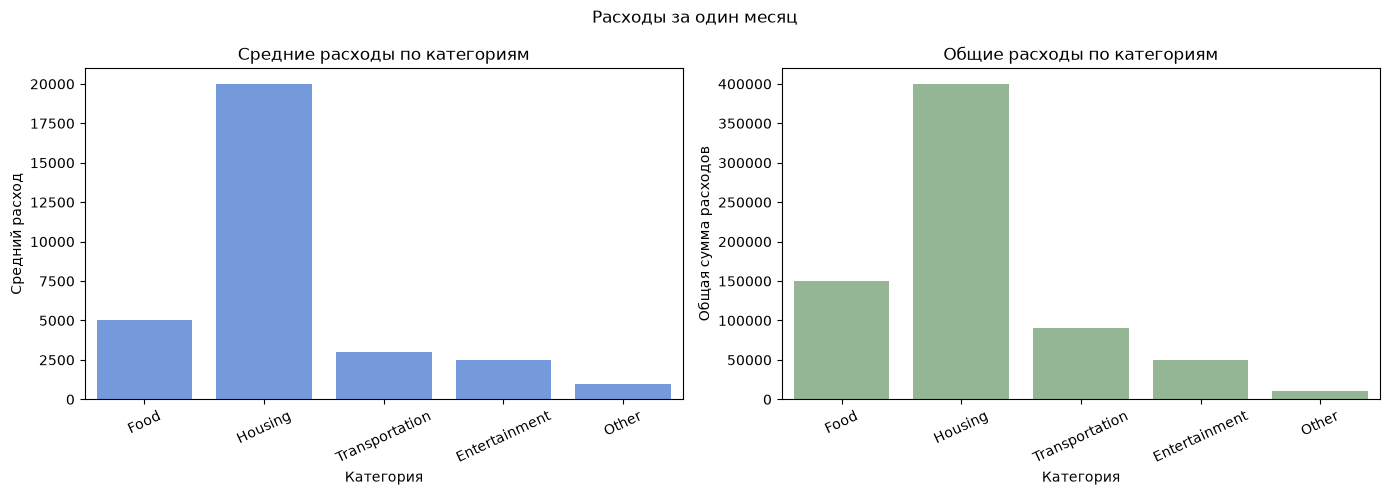

In [8]:
expenses = pd.DataFrame({
    'Category': ['Food', 'Housing', 'Transportation', 'Entertainment', 'Other'],
    'Mean': [5000, 20000, 3000, 2500, 1000],
    'Total': [150000, 400000, 90000, 50000, 10000]
})


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=expenses, x='Category', y='Mean', ax=axes[0],
            color='cornflowerblue')
axes[0].set_title('Средние расходы по категориям')
axes[0].set_xlabel('Категория')
axes[0].set_ylabel('Средний расход')
axes[0].tick_params(axis='x', rotation=25)

sns.barplot(data=expenses, x='Category', y='Total', ax=axes[1],
            color='darkseagreen')
axes[1].set_title('Общие расходы по категориям')
axes[1].set_xlabel('Категория')
axes[1].set_ylabel('Общая сумма расходов')
axes[1].tick_params(axis='x', rotation=25)

fig.suptitle('Расходы за один месяц')
plt.tight_layout()
plt.show()

**3. Вам предоставлены данные о доходах клиентов банка по разным категориям дохода. Ваша задача - построить boxplot для каждой категории дохода и определить, есть ли выбросы в данных, а также вывести их списком на экран. Для работы с выбросами рекомендую воспользоваться методом `quantile()`.**

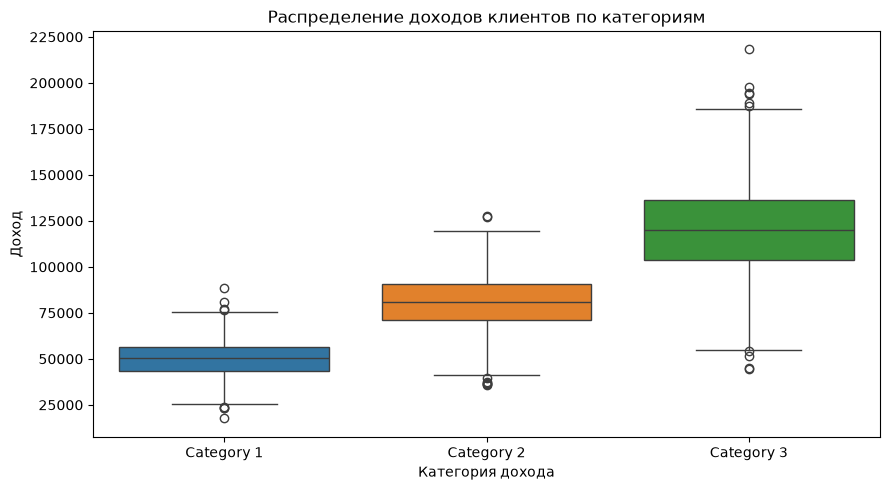

Category 1: границы [24091.08, 75912.45]
Выбросы (8): [23802.548959102558, 77201.69166589619, 88527.31490654721, 17587.326599309275, 80788.80808455238, 23031.133570584283, 23490.30191606988, 76323.8206483739]

Category 2: границы [40866.09, 120973.52]
Выбросы (8): [37271.86069054887, 36556.16932709466, 36916.06680077526, 36179.74274758089, 127896.61351767291, 39451.515605011446, 127066.22800489991, 35894.1704800358]

Category 3: границы [54715.70, 185607.19]
Выбросы (10): [44512.19610447937, 188991.50097277694, 197747.96390013403, 193727.36063271813, 194631.47506508525, 54106.30652457806, 187325.8415995124, 51312.37893186913, 218155.94266090816, 45221.60072748191]



In [9]:
# генерируем случайные данные о доходах клиентов банка
np.random.seed(42)
data = pd.DataFrame({
    'Category 1': np.random.normal(50000, 10000, 1000),
    'Category 2': np.random.normal(80000, 15000, 1000),
    'Category 3': np.random.normal(120000, 25000, 1000)
})


plt.figure(figsize=(9, 5))
sns.boxplot(data=data)
plt.title('Распределение доходов клиентов по категориям')
plt.xlabel('Категория дохода')
plt.ylabel('Доход')
plt.tight_layout()
plt.show()


outliers = {}
for column in data.columns:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    values = data.loc[
        (data[column] < lower_bound) | (data[column] > upper_bound),
        column
    ].tolist()
    outliers[column] = values
    print(f'{column}: границы [{lower_bound:.2f}, {upper_bound:.2f}]')
    print(f'Выбросы ({len(values)}): {values}\n')